In [1]:
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')
from analysis import collection, analysis, emg, plot, model
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import patches, lines
from pathlib import Path
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from joblib import dump, load
from analysis.offsets import offsets

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/methods/")

%matplotlib inline

In [2]:
movement_stacks = np.load("../subject_filtered_movement_stacks.npy")
movement_stacks.shape

(46, 2, 14, 64, 2000)

In [3]:
channels = np.arange(64)
n_timepoints = 2000
n_targets = 14
n_blocks = 2
# n_subjects = 46
subject_block_target_time_channel = np.tile(channels, (n_blocks,n_targets,n_timepoints,1))
print(subject_block_target_time_channel.shape,np.product(subject_block_target_time_channel.shape[:-1]))

timepoints = np.arange(n_timepoints)
targets = range(n_targets)
blocks = range(n_blocks)
# subjects = range(n_subjects)

(2, 14, 2000, 64) 56000


In [4]:
multi_index = pd.MultiIndex.from_product([timepoints,targets,blocks][::-1],names=["time", "target", "block"][::-1])

In [19]:
# for each subject
subject_idx = 29
subject_movement_stack = movement_stacks[subject_idx].transpose(0,1,3,2)
subject_movement_stack = subject_movement_stack.reshape(-1,64)
subject_movement_stack.shape

# make dataframe
movement_df = pd.DataFrame(subject_movement_stack,index=multi_index,columns=channels).drop(labels=56,axis=1).dropna()

In [20]:
import umap
reducer = umap.UMAP(n_components=2,n_neighbors=500,min_dist=1.0)
embedding = reducer.fit_transform(movement_df)

In [21]:
embedding_df = pd.DataFrame(embedding, index=movement_df.index)

In [22]:
hand_positions = [
    "Index Finger Up",    
    "Index Finger Down",
    "Middle Finger Up",    
    "Middle Finger Down",
    "Ring Finger Up",    
    "Ring Finger Down",
    "Little Finger Up",    
    "Little Finger Down",
    "Hand Open",    
    "Hand Grasp",
    "Wrist Up",    
    "Wrist Down",
    "Wrist In",    
    "Wrist Out"
]
len(hand_positions)

14

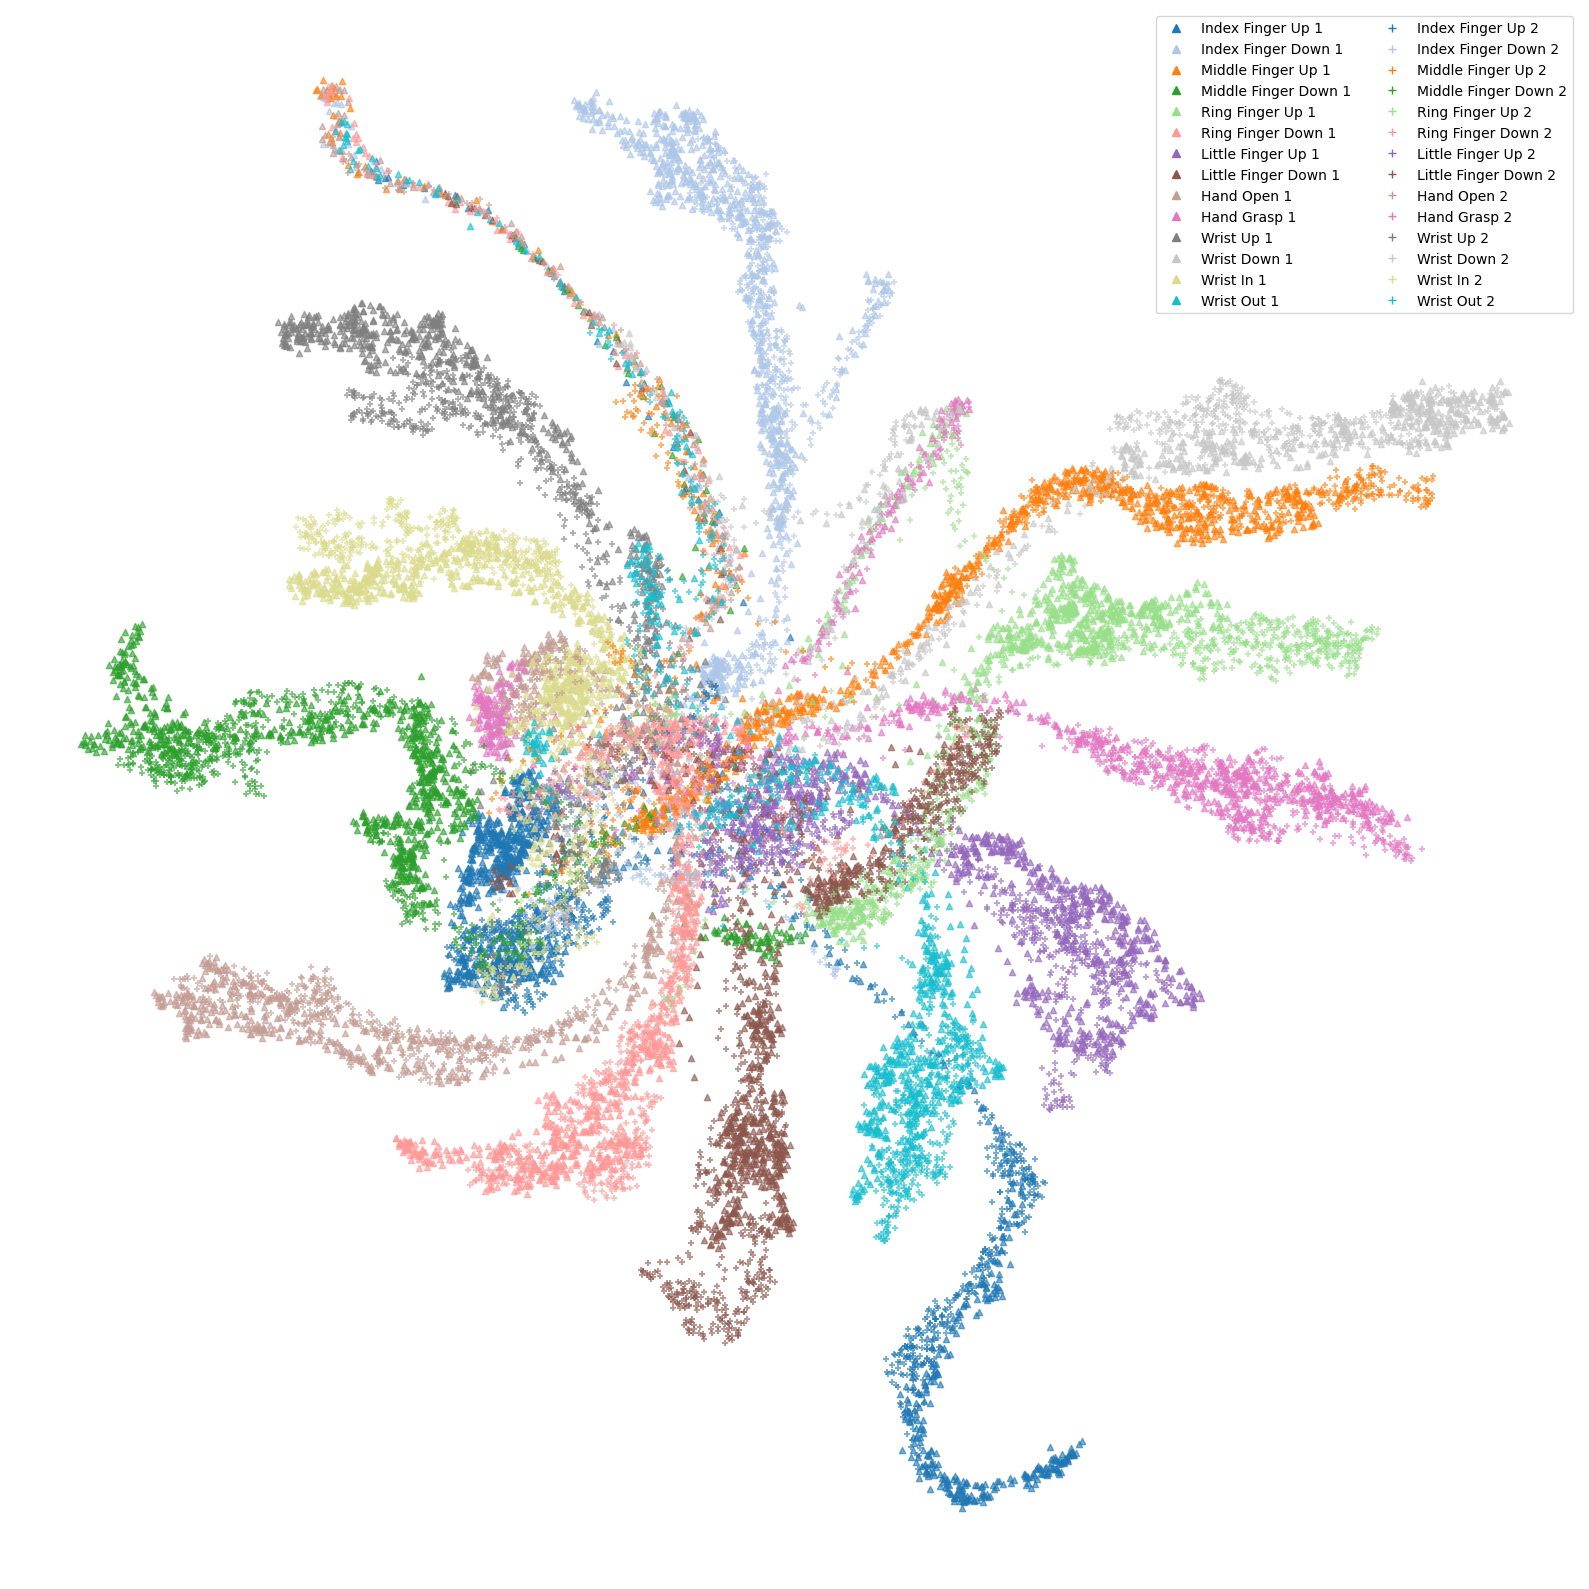

In [31]:
import matplotlib.lines as mlines

fig, ax = plt.subplots(1,1,figsize=(16,16))
block_colors = ["tab:red","tab:blue"]
block_markers = ["^","+"]
colormap = plt.colormaps["tab20"]
for block, block_df in embedding_df.groupby(level=0):
    for movement, mdf in block_df.groupby(level=1):
        mdf.plot(kind="scatter",x=0,y=1,alpha=0.6,marker=block_markers[block],ax=ax,color=colormap(movement/14))

handles = [mlines.Line2D([],[],marker=block_markers[0], color=colormap(i/14)) for i in range(14)] + [mlines.Line2D([],[],marker=block_markers[1], color=colormap(i/14)) for i in range(14)]
labels = [hp + " 1" for hp in hand_positions] + [hp + " 2" for hp in hand_positions]
ax.legend(handles=handles, labels=labels,loc=1,ncols=2)
ax.axis('off')
fig.tight_layout()


In [32]:
plot.save_figure(fig,"natural_movement_umap",image_path)

Figure saved to /Users/spencer/phd/phd/images/methods/natural_movement_umap.pdf


## PCA

In [28]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca = pca.fit_transform(movement_df)
pca_df = pd.DataFrame(pca, index=movement_df.index)

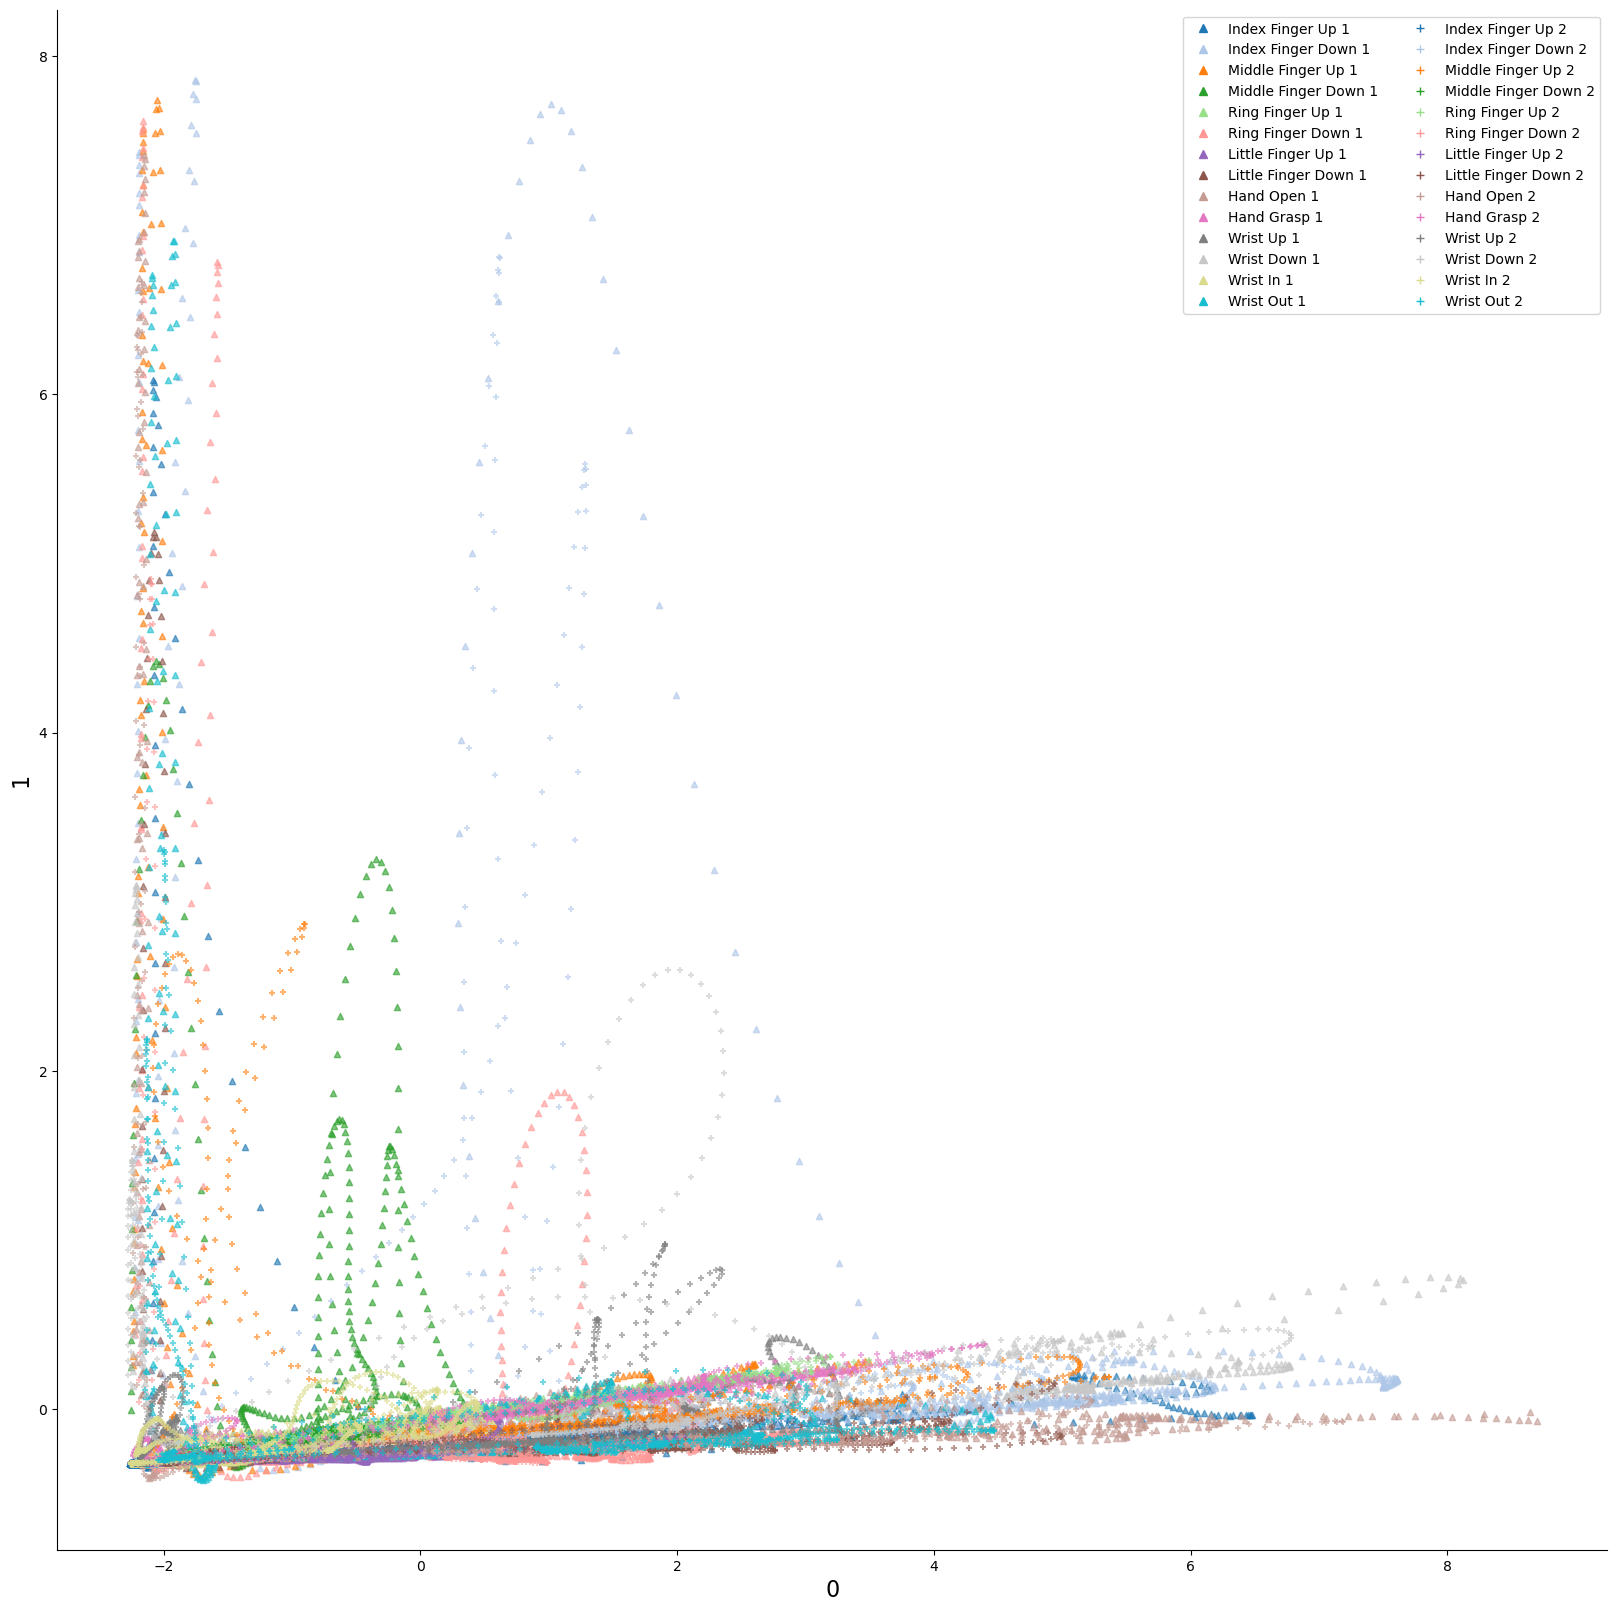

In [29]:
fig, ax = plt.subplots(1,1,figsize=(20,20))
block_colors = ["tab:red","tab:blue"]
block_markers = ["^","+"]
colormap = plt.colormaps["tab20"]
for block, block_df in pca_df.groupby(level=0):
    for movement, mdf in block_df.groupby(level=1):
        mdf.plot(kind="scatter",x=0,y=1,alpha=0.6,marker=block_markers[block],ax=ax,color=colormap(movement/14))

handles = [mlines.Line2D([],[],marker=block_markers[0], color=colormap(i/14)) for i in range(14)] + [mlines.Line2D([],[],marker=block_markers[1], color=colormap(i/14)) for i in range(14)]
labels = [hp + " 1" for hp in hand_positions] + [hp + " 2" for hp in hand_positions]
ax.legend(handles=handles, labels=labels,loc=1,ncols=2)

IndexError: list index out of range

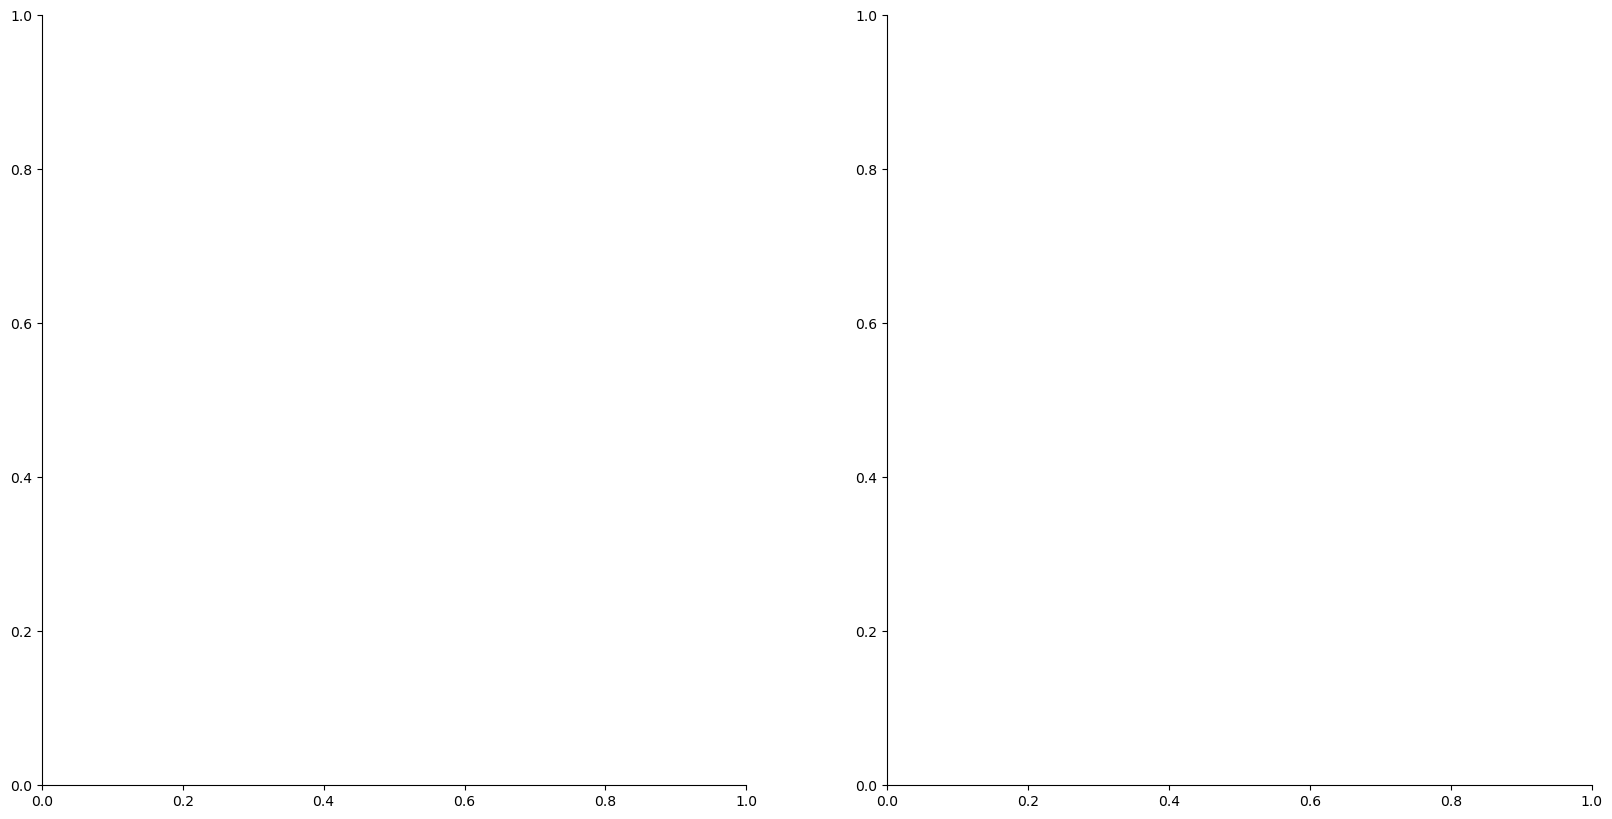

In [23]:
umap_fig, axes = plt.subplots(1,2,figsize=(20,10))

colors = ["tab:red","tab:blue","tab:green","tab:purple","tab:pink","tab:orange","tab:brown","tab:grey","tab:cyan","m","tab:olive","navy"]

block_names = movement_df.index.get_level_values("block").tolist()
target_names = movement_df.index.get_level_values("target").tolist()

time_indices = np.array(movement_df.index.get_level_values("time").tolist())
embedding_df.plot(kind="scatter",colorbar=False,x=0,y=1,s=2*np.ones(shape=(embedding_df.shape[0])),c=[colors[i] for i in target_names],colormap="Set3",alpha=0.6,ax=axes[0])
embedding_df.plot(kind="scatter",colorbar=False,x=0,y=1,s=2*np.ones(shape=(embedding_df.shape[0])),c=index_to_color(block_names),colormap="cividis",alpha=0.6,ax=axes[1])
for ax in axes:
    ax.set_frame_on(False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")

handles = [patches.Patch(color=c) for c in colors]
axes[0].legend(handles=handles, labels=[f"Target {i+1}" for i in range(12)],loc=1,ncols=2)

handles = [patches.Patch(color=mpl.colormaps["cividis"](i)) for i in [0.0,0.5,1.0]]
axes[1].legend(handles=handles, labels=["Early", "Middle", "Late"],loc=1)